In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit

from core import figstyle
from core.rings_plot import (stretched_xlim, GAMMA_C_N3, GAMMA_B_N3, plot_capacity_values,
                             add_network_inset, build_optimized_ring_graph, draw_weighted_network_on_ax,
                             plot_dissipation_N2, plot_fig2b_N2, plot_Figure3, add_insets_to_Figure3,
                             plot_Figure4, plot_curves_fixed_betas, plot_curves_fixed_gammas,
                             add_network_inset_xy)
from core.rings_calc import (gamma_c_vs_N_closed_form, get_capacities_all_branches, k_symmetric,
                             build_weighted_ring_graph_from_kvec, kvec_N2_mu0_broken, get_Figure10_data)

## Supplementary figure 1

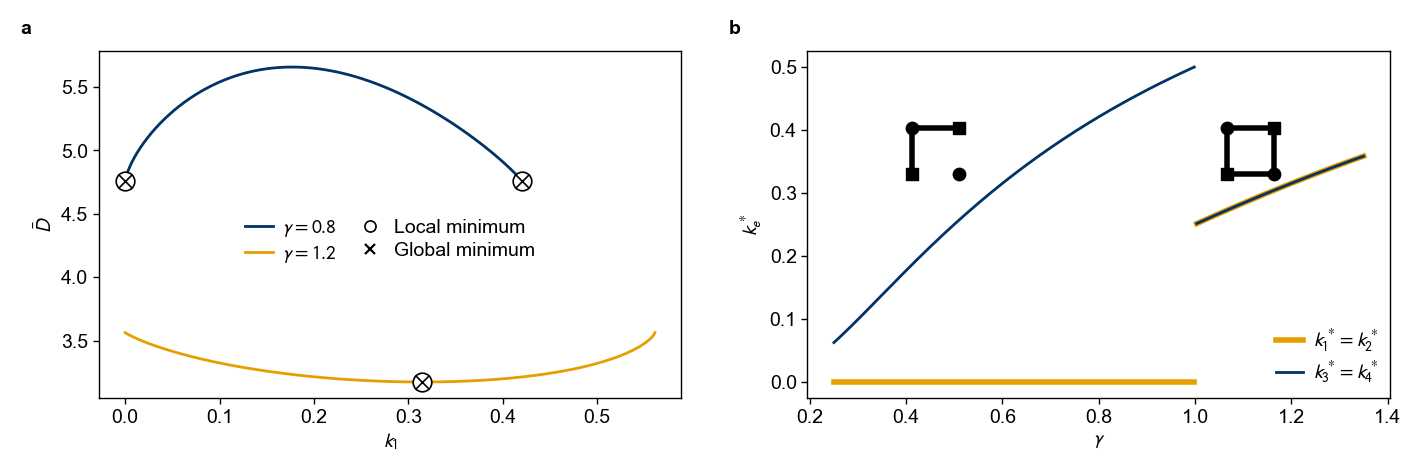

In [2]:
# Define plot characteristics
figstyle.apply()

legend_elements = [
    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='white', markeredgecolor='black', markeredgewidth=0.6, markersize=4.0, label='Local minimum'),
    Line2D([0], [0], marker='x', linestyle='None', color='black', markeredgewidth=0.8, markersize=3.4, label='Global minimum')
]

# Define system parameters
mu = 0.0
beta = 1.0
kappa = 1.0

gammas_ab = [0.8, 1.2]
gammas_b = np.linspace(0.25, 1.35, 220)

width, height = 179.0, 62.0
left, right = 12.0, 3.0
avail = width - left - right

row1_bottom, row1_height = 11.0, 44.0

row1_gap = 16.0
row1_w = (avail - row1_gap) / 2.0

def rect(x, y, w, h):
    return [x / width, y / height, w / width, h / height]

# Figure
fig = plt.figure(figsize=figstyle.mm(width, height))

# Subplot (a)
ax_a = fig.add_axes(rect(left, row1_bottom, row1_w, row1_height))
plot_dissipation_N2(gammas_ab, mu=mu, beta=beta, kappa=kappa, ax=ax_a, legend_elements=legend_elements,
                    lw=1.0, s_circle=45, s_cross=26, marker_lw=0.6, legend_loc="center", legend_ncol=2)
ax_a.get_legend().set_bbox_to_anchor((0.5, 0.45), transform=ax_a.transAxes)

# Subplot (b)
ax_b = fig.add_axes(rect(left + row1_w + row1_gap, row1_bottom, row1_w, row1_height))
plot_fig2b_N2(gammas_b, kappa=kappa, ax=ax_b, lw_thick=2.0, lw_thin=1.0, legend_loc="lower right")

# Inset positions
ax_inset1 = ax_b.inset_axes([0.12, 0.60, 0.28, 0.36])
ax_inset2 = ax_b.inset_axes([0.66, 0.60, 0.28, 0.36])

# Representative networks for selected gammas
gamma_left = 0.7
gamma_right = 1.2
k_left = kvec_N2_mu0_broken(gamma_left, kappa=kappa, which="left")
k_right = k_symmetric(2, gamma_right, kappa=kappa)

G_left = build_weighted_ring_graph_from_kvec(k_left)
G_right = build_weighted_ring_graph_from_kvec(k_right)

pos_square_4 = {
    0: (0, 0),
    1: (-0.15, 0),
    2: (-0.15, -0.15),
    3: (0, -0.15),
}

draw_weighted_network_on_ax(G_left,  ax_inset1, pos_square_4, color="black", node_size=20, lw_scale=0.22)
draw_weighted_network_on_ax(G_right, ax_inset2, pos_square_4, color="black", node_size=20, lw_scale=0.22)


panels = [("a", left, row1_bottom + row1_height),
          ("b", left + row1_w + row1_gap, row1_bottom + row1_height)]

for letter, x, y in panels:
    figstyle.panel_label(fig, letter, (x - 10.0) / width, (y + 4.0) / height)

fig.savefig("FigureS1.pdf", format="pdf")
plt.show()

# Figure 2 

Symmetry breaking in an elementary ring network with $N = 2, \mu = 0, \beta = 1.0, \kappa = 1$.

(a): The expected dissipation $\bar D(k_1)$ for two values of the scaling exponent $\gamma = \{0.8,  1.2\}$.
- For $\gamma<1$ there are two minima on the boundary of the domain corresponding to symmetry-broken states with $k^*_1 = k^*_2=0$ and $k_3=k_4= 2^{-1/\gamma} \kappa$ or $k^*_3 = k^*_4=0$ and $k_1=k_2= 2^{-1/\gamma} \kappa$.
- For $\gamma>1$ there is a single local minimum corresponding to a symmetric state $k^*_1 = k^*_2= k^*_3 = k^*_4= \kappa \cdot 4^{-1/\gamma} \kappa$. 

(b): The optimal edge capacities as a function of the scaling exponent $\gamma$. The insets show the optimal network structure for $\gamma=0.7$ and $\gamma=1.2$.

Symmetry breaking via an exchange of local and global minima in an elementary ring network with $N=3$ and $\mu=0$. We show the expected dissipation $\bar D(k_1,k_3)$ for three values of the scaling exponent $\gamma$.

(a) For $\gamma=0.55$ there are three minima on the boundary of the domain corresponding to symmetry-broken states. The symmetric state is a local minimum but has a higher value of $\bar D$ than the symmetry-broken state.

(b) For $\gamma=0.6$ the minima exchange roles: The symmetric state is the global minimum while the symmetry-broken states are local minima with a higher value of the dissipation. No local minimum is lost during the transition to symmetry breaking.

(c) For $\gamma=1.05$, $\bar D$ is convex and there is a single minimum corresponding to the symmetric state.

The optimal edge capacities as a function of the scaling exponent $\gamma$ in an elementary ring network with $N=3$ and $\mu =0$. The solid lines correspond to global minima and the dashed lines correspond to local minima.

The symmetry-breaking transition takes place at a critical value $\gamma_c=\ln(3/2)/\ln(2) \approx 0.585$ where the roles of the local and global minima exchange (dotted line).

The local minima undergo a bifurcation and vanish at $\gamma_b=1$ (dash-dotted line).

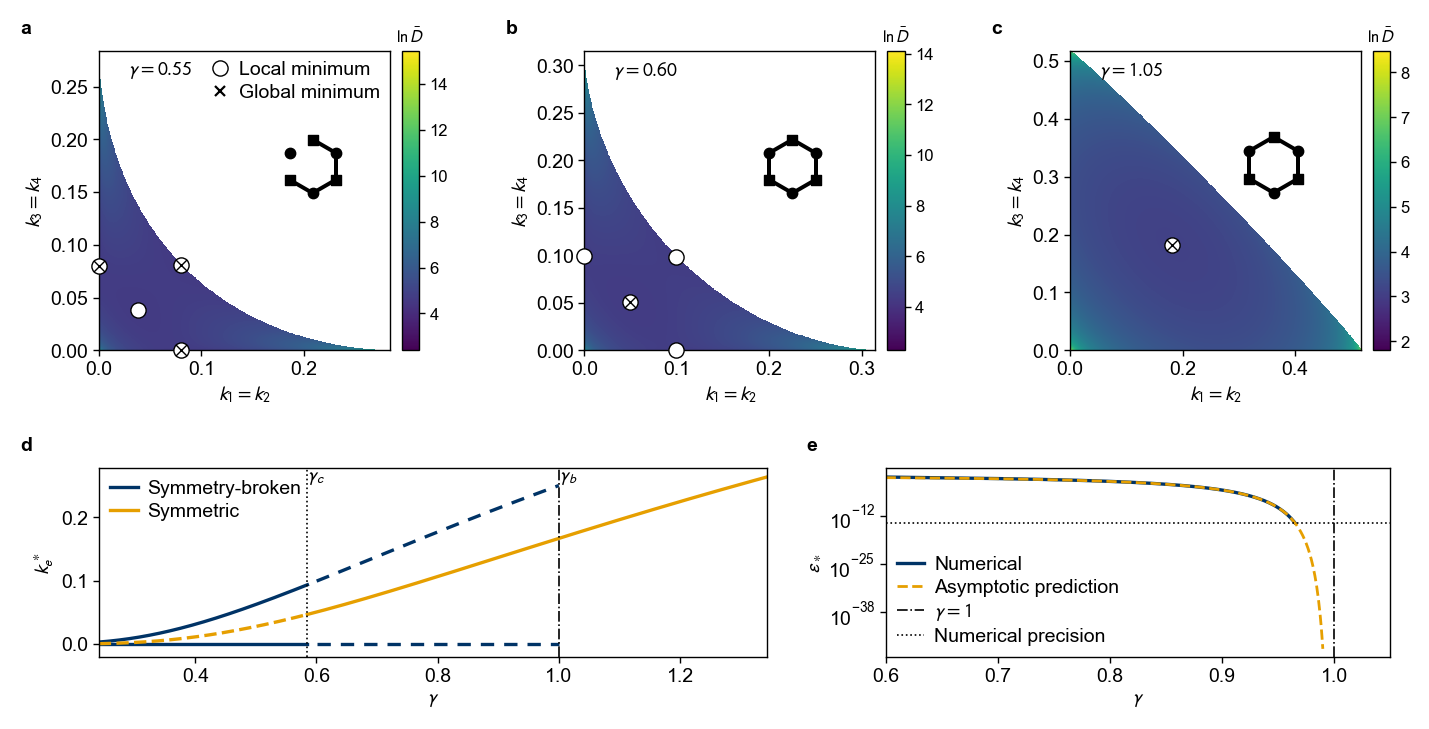

In [3]:
# Define plot characteristics
figstyle.apply()

# Define system parameters
mu = 0.0
beta = 1.0
kappa = 1.0

gammas_abc = [0.55, 0.60, 1.05]

grid = 620
minima_grid = 260

width, height = 179.0, 91.0
left, right = 12.0, 3.0
avail = width - left - right

row1_bottom, row1_height = 48.0, 38.0   # a, b, c
row2_bottom, row2_height =  9.0, 24.0   # d, e

cb_w, cb_pad, row1_gap = 2.2, 1.5, 21.0
row1_w = (avail - 3 * (cb_pad + cb_w) - 2 * row1_gap) / 3.0
block_w = row1_w + cb_pad + cb_w

row2_gap = 15.0
row2_w_d = (avail - row2_gap) * 0.57
row2_w_e = (avail - row2_gap) * 0.43
e_left = left + row2_w_d + row2_gap

s_circle, s_cross, marker_lw = 30, 17, 0.5

legend_minima = [
    Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="white",
           markeredgecolor="black", markeredgewidth=marker_lw,
           markersize=np.sqrt(s_circle), label="Local minimum"),
    Line2D([0], [0], marker="x", linestyle="None", color="black",
           markeredgewidth=0.8, markersize=3.4, label="Global minimum"),
]
legend_minima_labels = ["Local minimum", "Global minimum"]

def rect(x, y, w, h):
    return [x / width, y / height, w / width, h / height]

# Figure
fig = plt.figure(figsize=figstyle.mm(width, height))

# Subplots (a), (b) and (c)
for i, gamma in enumerate(gammas_abc):
    x = left + i * (block_w + row1_gap)
    ax = fig.add_axes(rect(x, row1_bottom, row1_w, row1_height))
    cax = fig.add_axes(rect(x + row1_w + cb_pad, row1_bottom, cb_w, row1_height))

    plot_Figure3(gamma, mu=mu, beta=beta, kappa=kappa, grid=grid, minima_grid=minima_grid,
                 ax=ax, cax=cax, label_above=True, cbar_labelsize=6.0,
                 s_circle=s_circle, s_cross=s_cross, marker_lw=marker_lw, gamma_label_xy=(0.10, 0.97))
    add_insets_to_Figure3(ax, gamma, kappa=kappa, node_size=14, lw_scale=0.24)

    if i == 0:
        ax.legend(legend_minima, legend_minima_labels, loc="upper right",
                  fontsize=figstyle.FONT_LEGEND, frameon=False,
                  handletextpad=0.3, borderaxespad=0.2)

# Subplot (d)
ax_d = fig.add_axes(rect(left, row2_bottom, row2_w_d, row2_height))

gap1 = left + block_w + row1_gap / 2.0
gap2 = left + 2 * block_w + row1_gap + row1_gap / 2.0
gamma_min, gamma_max = stretched_xlim(GAMMA_C_N3, GAMMA_B_N3, (gap1 - left) / avail, (gap2 - left) / avail)

plot_Figure4(ax=ax_d, kappa=kappa, gamma_min=gamma_min, gamma_max=gamma_max,
             lw=1.2, guide_lw=0.6, legend_fontsize=figstyle.FONT_LEGEND, legend_loc="upper left")

ylo, yhi = ax_d.get_ylim()
ax_d.text(GAMMA_C_N3, yhi, r"$\gamma_c$", ha="left", va="top", fontsize=7.0)
ax_d.text(GAMMA_B_N3, yhi, r"$\gamma_b$", ha="left", va="top", fontsize=7.0)

# Subplot (e), next to (d)
ax_e = fig.add_axes(rect(e_left, row2_bottom, row2_w_e, row2_height))

eps_vals = np.logspace(-14, -0.5, 2500)
gamma_scan = np.linspace(0.6, 0.99, 500)
numerical_precision = 1e-14

gamma_numerical, eps_numerical, gamma_asymptotic, eps_asymptotic = get_Figure10_data(
    gamma_scan, eps_vals, beta=beta, kappa=kappa, numerical_precision=numerical_precision)

ax_e.plot(gamma_numerical, eps_numerical, lw=1.2, color="#003366", label="Numerical")
ax_e.plot(gamma_asymptotic, eps_asymptotic, ls="--", lw=1.0, color="#E69F00", label="Asymptotic prediction")
ax_e.axvline(1.0, ls="dashdot", color="k", lw=0.6, label=r"$\gamma=1$")
ax_e.axhline(numerical_precision, ls=":", color="k", lw=0.6, label="Numerical precision")
ax_e.set_yscale("log")
ax_e.set_xlabel(r"$\gamma$")
ax_e.set_ylabel(r"$\varepsilon_\ast$")
ax_e.set_xlim(0.6, 1.05)
ax_e.legend(loc="lower left", ncol=1)

panels = [("a", left, row1_bottom + row1_height),
          ("b", left + block_w + row1_gap, row1_bottom + row1_height),
          ("c", left + 2 * (block_w + row1_gap), row1_bottom + row1_height),
          ("d", left, row2_bottom + row2_height),
          ("e", e_left, row2_bottom + row2_height)]

for letter, x, y in panels:
    figstyle.panel_label(fig, letter, (x - 10.0) / width, (y + 4.0) / height)

fig.savefig("Figure2.pdf", format="pdf")
plt.show()

# Figure 3

Top row (a, b, c): Phase diagram of the optimal network structure for the ring model class for $\mu=1$ The insets visualize the optimal network structure in the corresponding regions. We plot the smallest edge capacity in the optimal network $\min_{e \in \mathcal{E}} k_e^*$ as a function of the fluctuation strength $\beta$ and the scaling exponent $\gamma$ for (a) $N=2$, (b) $N=3$, and (c) $N=4$. Strong symmetry breaking is indicated by $\min_{e \in \mathcal{E}} k_e^* = 0$, i.e.,~one edge is missing in the optimal networks. The stability boundaries of the symmetry broken state are denoted in white dash-dotted lines. 

(d): Optimal network state as a function of the scaling exponent $\gamma$ for $N=2$. At $\beta=0.2$, the transtion from strongly symmetry-broken to symmetric state occurs via a weakly symmetry-broken state.

(e): Optimal network state as a function of the fluctuation strength $\beta$ and $N=2$ for $\gamma=0.55$. There is a reentrant phase transition from one type of strongly symmetry-broken state to symmetric and back to another strongly symmetry-broken state, via distinct weakly symmetry-broken states.

(f): Scaling with system size $N$ of the minimal value $\gamma_c$ for which we observe the phase transition between symmetry-broken and symmetric states, for $\mu=1$.

(g): Capacity $k_c$ of the symmetric configuration at $\gamma_c$, i.e., the jump of $\min_e k_e^*$ at the transition, as a function of $N$. 

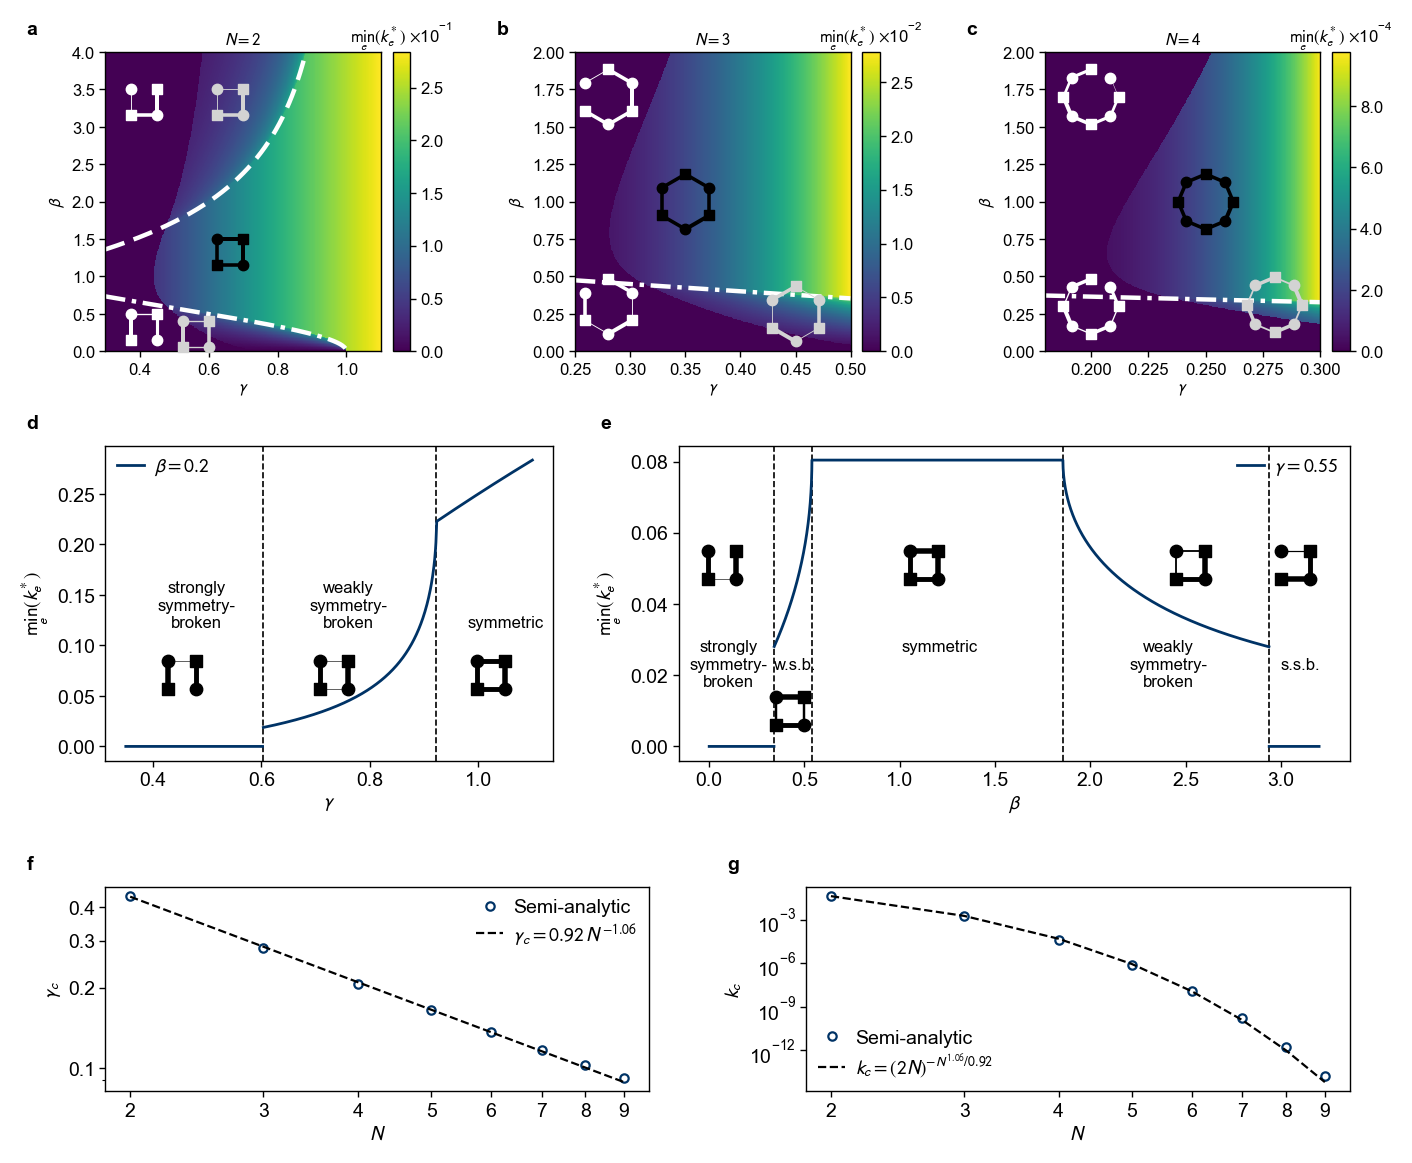

In [4]:
# Define plot characteristics
figstyle.apply()

# White stability boundaries: dash-dotted for the lower branch on every N,
# dashed for the boundary that exists only at N = 2.
LW_BOUNDARY = 1.6
DASHDOT = (0, (4.5, 1.5, 1, 1.5))
DASHED = (0, (4.5, 2.2))

# Define system parameters
mu = 1.0
kappa = 1.0

width, height = 179.0, 154.0
left, right = 12.0, 9.0
avail = width - left - right

row1_bottom, row1_height = 106.0, 38.0
row2_bottom, row2_height = 54.0, 40.0
row3_bottom, row3_height = 12.0, 26.0

cb_w, cb_pad, row1_gap = 2.2, 1.5, 21.0
row1_w = (avail - 3 * (cb_pad + cb_w) - 2 * row1_gap) / 3
block_w = row1_w + cb_pad + cb_w

row2_gap = 16.0
row2_w_d = (avail - row2_gap) * 0.40
row2_w_e = (avail - row2_gap) * 0.60

row3_gap = 20.0
row3_w = (avail - row3_gap) / 2


def rect(x, y, w, h):
    """Axes rectangle in figure fractions from millimetre coordinates."""
    return [x / width, y / height, w / width, h / height]

# Figure
fig = plt.figure(figsize=figstyle.mm(width, height))

# Subplots (a), (b) and (c): phase diagrams for N = 2, 3 and 4
panel_specs = [
    (2, np.linspace(0.30, 1.10, 500), np.linspace(0.0, 4.0, 500),
     [(0.45, 0.5, "white"), (0.45, 3.5, "white"), (0.7, 1.5, "black"),
      (0.7, 3.5, "lightgray"), (0.6, 0.4, "lightgray")]),
    (3, np.linspace(0.25, 0.50, 500), np.linspace(0.0, 2.0, 500),
     [(0.28, 0.3, "white"), (0.28, 1.7, "white"), (0.35, 1.0, "black"),
      (0.45, 0.25, "lightgray")]),
    (4, np.linspace(0.18, 0.30, 500), np.linspace(0.0, 2.0, 500),
     [(0.2, 0.3, "white"), (0.2, 1.7, "white"), (0.25, 1.0, "black"),
      (0.28, 0.31, "lightgray")]),
]

for i, (N, gamma_values, beta_values, insets) in enumerate(panel_specs):
    capacity_values, _ = get_capacities_all_branches(N, mu, beta_values, gamma_values, verbose=False)

    x = left + i * (block_w + row1_gap)
    ax = fig.add_axes(rect(x, row1_bottom, row1_w, row1_height))
    cax = fig.add_axes(rect(x + row1_w + cb_pad, row1_bottom, cb_w, row1_height))

    plot_capacity_values(capacity_values, N, beta_values, gamma_values,
                         ax=ax, cax=cax, fontsize=6.0, label_above=True,
                         N_label_xy=None)

    # Local stability boundaries of the symmetric branch
    with np.errstate(invalid="ignore"):
        factor = np.sqrt(3.0 * mu ** 2 / (N ** 2 - 1))
        beta_lower = factor * np.sqrt((1 - gamma_values) / (1 + gamma_values))
        ax.plot(gamma_values, beta_lower, color="white", lw=LW_BOUNDARY, ls=DASHDOT)
        if N == 2:
            beta_upper = np.sqrt((1 + gamma_values) / (1 - gamma_values))
            ax.plot(gamma_values, beta_upper, color="white", lw=LW_BOUNDARY, ls=DASHED)

    ax.set_xlim(gamma_values[0], gamma_values[-1])
    ax.set_ylim(beta_values[0], beta_values[-1])

    for gamma_i, beta_i, color_i in insets:
        Gres, _, _ = build_optimized_ring_graph(N=N, beta=beta_i, gamma=gamma_i, mu=mu)
        add_network_inset(ax, Gres, gamma=gamma_i, beta=beta_i, size=0.25,
                          color=color_i, node_size=14, lw_scale=0.16)

# Subplot (d): optimal state versus gamma at fixed beta
ax_d = fig.add_axes(rect(left, row2_bottom, row2_w_d, row2_height))

fixed_betas = [0.2]
gamma_values_d = np.linspace(0.35, 1.1, 1000)
minK_d, branch_labels_d = get_capacities_all_branches(2, mu, fixed_betas, gamma_values_d,
                                                      kappa=kappa, verbose=False)

def strong_breaking_boundaries(y, x):
    """min_e k is exactly zero in the strongly symmetry-broken phase."""
    z = np.asarray(y, dtype=float) <= 0.0
    i = np.where(z[:-1] != z[1:])[0]
    return 0.5 * (np.asarray(x)[i] + np.asarray(x)[i + 1])

breaks_d = strong_breaking_boundaries(minK_d[0], gamma_values_d)
gamma_alt = (mu**2 - fixed_betas[0]**2) / (mu**2 + fixed_betas[0]**2)
jumps_d = np.sort(np.append(breaks_d, gamma_alt))

plot_curves_fixed_betas(fixed_betas, gamma_values_d, minK_d, branch_labels_d,
                        ax=ax_d, fontsize=7.0, lw=1.0, jump_lw=0.6,
                        colors=["#003366"], legend_loc="upper left",
                        jump_positions=jumps_d, break_positions=breaks_d)


for gamma_i, x_i, txt in [(0.40, 0.48, "strongly\nsymmetry-\nbroken"),
                          (0.70, 0.76, "weakly\nsymmetry-\nbroken"),
                          (1.00, 1.05, "symmetric")]:
    G_i, _, _ = build_optimized_ring_graph(2, beta=0.2, gamma=gamma_i, mu=mu)
    add_network_inset_xy(ax_d, G_i, x=x_i, y=0.085, size=0.24, color="black",
                     node_size=20, lw_scale=0.22)
    ax_d.text(x_i, 0.115, txt, ha="center", va="bottom", fontsize=6.0)

# Subplot (e): reentrant behaviour versus beta at fixed gamma
ax_e = fig.add_axes(rect(left + row2_w_d + row2_gap, row2_bottom, row2_w_e, row2_height))

fixed_gammas = [0.55]
beta_values_e = np.linspace(0.0, 3.2, 5000)
minK_e, branch_labels_e = get_capacities_all_branches(2, mu, beta_values_e, fixed_gammas,
                                                      kappa=kappa, verbose=False)

g0 = fixed_gammas[0]
beta_alt = mu * np.sqrt(3 / (2**2 - 1)) * np.sqrt((1 - g0) / (1 + g0))
beta_block = mu * np.sqrt((1 + g0) / (1 - g0))
breaks_e = strong_breaking_boundaries(minK_e[:, 0], beta_values_e)
jumps_e = np.sort(np.concatenate([breaks_e, [beta_alt, beta_block]]))

plot_curves_fixed_gammas(beta_values_e, fixed_gammas, minK_e, branch_labels_e,
                         ax=ax_e, fontsize=7.0, lw=1.0, jump_lw=0.6,
                         colors=["#003366"], legend_loc="upper right",
                         jump_positions=jumps_e, break_positions=breaks_e)

for beta_i, x_i, y_i in [(0.10, 0.14, 0.055), (0.46, 0.50, 0.014), (1.00, 1.20, 0.055),
                         (2.40, 2.60, 0.055), (3.05, 3.15, 0.055)]:
    G_i, _, _ = build_optimized_ring_graph(2, beta=beta_i, gamma=0.55, mu=mu)
    add_network_inset_xy(ax_e, G_i, x=x_i, y=y_i, size=0.24, color="black",
                         node_size=20, lw_scale=0.22)

for x_i, y_i, txt in [(0.10, 0.0300, "strongly\nsymmetry-\nbroken"),
                      (0.45, 0.0250, "w.s.b."),
                      (1.21, 0.0300, "symmetric"),
                      (2.41, 0.0300, "weakly\nsymmetry-\nbroken"),
                      (3.10, 0.0250, "s.s.b.")]:
    ax_e.text(x_i, y_i, txt, ha="center", va="top", fontsize=6.0)

# Subplot (f): scaling of the critical exponent with system size
ax_f = fig.add_axes(rect(left, row3_bottom, row3_w, row3_height))

# Find critical gamma_c over a range of N values
N_values = np.arange(2, 10, 1)
mu = 1.0
gamma_c, beta_c = gamma_c_vs_N_closed_form(N_values, mu)

def power_law(N, c, alpha):
    return c * N ** (-alpha)

def k_crit_function(N, c, alpha):
    return (2 * N) ** (-N ** alpha / c)

popt, pcov = curve_fit(power_law, N_values, gamma_c)
c_fit, alpha_fit = popt

ax_f.loglog(N_values, gamma_c, "o", mfc="none", mec="#003366", mew=0.8, ms=3.0,
            label="Semi-analytic")
ax_f.loglog(N_values, power_law(N_values, *popt), "--", color="k", lw=0.8,
            label=rf"$\gamma_c = {c_fit:.2f}\,N^{{-{alpha_fit:.2f}}}$")
ax_f.set_xlabel(r"$N$")
ax_f.set_ylabel(r"$\gamma_c$")
ax_f.set_xticks(N_values)
ax_f.set_xticklabels([str(n) for n in N_values])
ax_f.set_yticks([0.1, 0.2, 0.3, 0.4])
ax_f.set_yticklabels(["0.1", "0.2", "0.3", "0.4"])
ax_f.legend(loc="upper right")

# Subplot (g): characteristic capacity at the transition
ax_g = fig.add_axes(rect(left + row3_w + row3_gap, row3_bottom, row3_w, row3_height))

k_cusp = np.array([(2 * N_values[i]) ** (-1.0 / gamma_c[i]) for i in range(len(N_values))])

ax_g.loglog(N_values, k_cusp, "o", mfc="none", mec="#003366", mew=0.8, ms=3.0,
            label="Semi-analytic")
ax_g.loglog(N_values, k_crit_function(N_values, *popt), "--", color="k", lw=0.8,
            label=rf"$k_c = (2N)^{{-N^{{{alpha_fit:.2f}}}/{c_fit:.2f}}}$")
ax_g.set_xlabel(r"$N$")
ax_g.set_ylabel(r"$k_c$")
ax_g.set_xticks(N_values)
ax_g.set_xticklabels([str(n) for n in N_values])
ax_g.legend(loc="lower left")

# Panel labels
panels = [("a", left, row1_bottom + row1_height),
          ("b", left + block_w + row1_gap, row1_bottom + row1_height),
          ("c", left + 2 * (block_w + row1_gap), row1_bottom + row1_height),
          ("d", left, row2_bottom + row2_height),
          ("e", left + row2_w_d + row2_gap, row2_bottom + row2_height),    
          ("f", left, row3_bottom + row3_height),
          ("g", left + row3_w + row3_gap, row3_bottom + row3_height)]


for letter, x, y in panels:
    figstyle.panel_label(fig, letter, (x - 10.0) / width, (y + 4.0) / height)

fig.savefig("Figure3.pdf", format="pdf")
plt.show()

Fit uncertainty:

In [5]:
c_err, alpha_err = np.sqrt(np.diag(pcov))
print(f"c = {c_fit:.3f} ± {c_err:.3f}, alpha = {alpha_fit:.3f} ± {alpha_err:.3f}")

c = 0.915 ± 0.010, alpha = 1.063 ± 0.010
